# 01 — Audit des données (partie 4.1)

**But :** regarder les données *avant* tout modèle. On répond à :
1. Quelle est la longueur des textes ?
2. Combien de valeurs a chaque argument ?
3. Les conclusions se répètent-elles, et passent-elles d'un split à l'autre ?
4. Y a-t-il des doublons (exacts, après normalisation) et des doublons aux labels contradictoires ?

On décrit train, val **et** test : décrire le test est autorisé (Q1 le demande) ; ce qui est interdit, c'est d'y **prendre une décision**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from valeval.data import load_split, VALUES

pd.set_option("display.max_colwidth", 120)
SPLITS = {"train": "training", "val": "validation", "test": "test"}
d = {nom: load_split(fichier) for nom, fichier in SPLITS.items()}
{nom: df.shape for nom, df in d.items()}

{'train': (5393, 24), 'val': (1896, 24), 'test': (1576, 24)}

## 0. À quoi ressemble un argument ?
Chaque ligne = une conclusion, une position (stance), une prémisse, et 20 colonnes 0/1.
Ci-dessous, on affiche pour chaque argument **la liste des valeurs à 1** (plus lisible que 20 colonnes).

In [2]:
train = d["train"]
apercu = train[["id", "conclusion", "stance", "premise"]].head(8).copy()
apercu["valeurs"] = train[VALUES].head(8).apply(lambda r: [v for v in VALUES if r[v] == 1], axis=1)
apercu

,id,conclusion,stance,premise,valeurs
0,A01002,We should ban human cloning,in favor of,we should ban human cloning as it will only cause huge issues when you have a bunch of the same humans running aroun...,[Security: societal]
1,A01005,We should ban fast food,in favor of,fast food should be banned because it is really bad for your health and is costly.,[Security: personal]
2,A01006,We should end the use of economic sanctions,against,sometimes economic sanctions are the only thing that will get the corrupt governments to take action,"[Power: dominance, Security: societal]"
3,A01007,We should abolish capital punishment,against,capital punishment is sometimes the only option to keep criminals from committing more crimes.,"[Security: societal, Conformity: rules, Universalism: concern]"
4,A01008,We should ban factory farming,against,"factory farming allows for the production of cheap food, which is a necessity for families surviving on a low income.","[Security: personal, Benevolence: caring, Universalism: concern]"
5,A01009,We should fight for the abolition of nuclear weapons,against,nuclear weapons help keep the peace in uncertain times,"[Security: societal, Universalism: concern]"
6,A01010,We should prohibit school prayer,against,it should be allowed if the student wants to pray as long as it is not interfering with his classes,"[Self-direction: thought, Self-direction: action, Tradition, Universalism: concern]"
7,A01011,We should abolish the three-strikes laws,in favor of,three strike laws can cause young people to be put away for life without a chance to straight out their life,"[Achievement, Face, Benevolence: caring, Universalism: tolerance, Universalism: objectivity]"


## 1. Longueur des textes (en mots)

In [3]:
lignes = []
for nom, df in d.items():
    for champ in ["conclusion", "premise"]:
        n = df[champ].str.split().str.len()
        lignes.append({"split": nom, "champ": champ, "moyenne": round(n.mean(), 1),
                       "médiane": n.median(), "min": n.min(), "p95": n.quantile(.95), "max": n.max()})
pd.DataFrame(lignes)

,split,champ,moyenne,médiane,min,p95,max
0,train,conclusion,6.4,5.0,4,11.0,35
1,train,premise,21.6,19.0,3,43.0,133
2,val,conclusion,6.6,7.0,4,11.0,25
3,val,premise,21.9,19.0,5,44.0,134
4,test,conclusion,5.7,5.0,4,12.0,24
5,test,premise,21.6,18.0,4,43.0,139


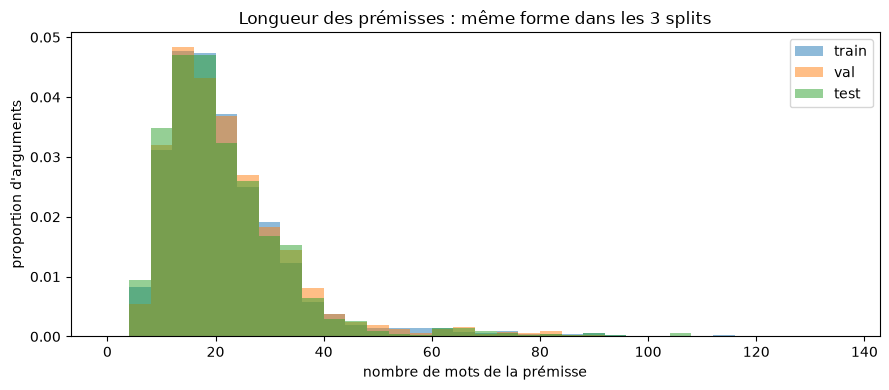

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for nom, df in d.items():
    ax.hist(df.premise.str.split().str.len(), bins=range(0, 140, 4), alpha=.5, density=True, label=nom)
ax.set(xlabel="nombre de mots de la prémisse", ylabel="proportion d'arguments",
       title="Longueur des prémisses : même forme dans les 3 splits")
ax.legend(); plt.tight_layout(); plt.savefig("../figures/audit_longueur_premisses.png", dpi=120); plt.show()

**Lecture :** les prémisses font ~20 mots, presque toutes < 45 mots. Les 3 courbes se superposent :
train, val et test ont la même longueur. Conséquence (partie E) : une longueur max de 128 tokens suffit pour conclusion + position + prémisse.

## 2. Nombre de valeurs par argument

In [5]:
nv = {nom: df[VALUES].sum(axis=1) for nom, df in d.items()}
pd.DataFrame({nom: s.value_counts().sort_index() for nom, s in nv.items()}).fillna(0).astype(int).T.assign(
    moyenne=[round(s.mean(), 2) for s in nv.values()])

,0,1,2,3,4,5,6,7,8,9,moyenne
train,1,411,1107,1495,1261,676,302,101,34,5,3.41
val,0,156,386,562,418,234,94,31,13,2,3.35
test,0,181,415,457,308,147,56,10,2,0,3.03


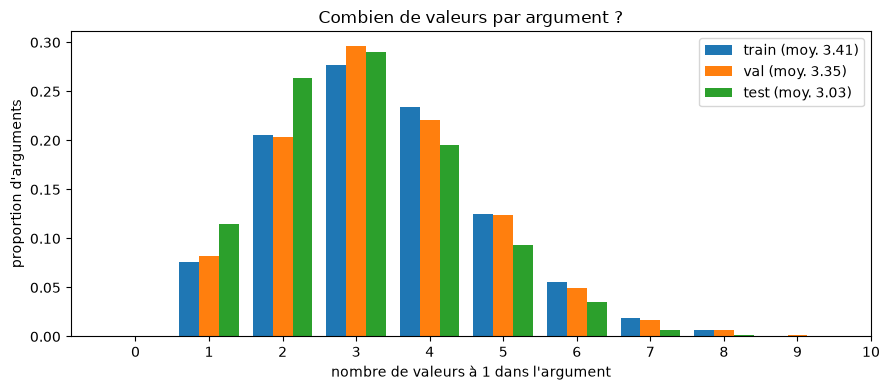

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
largeur = .27
for i, (nom, s) in enumerate(nv.items()):
    p = s.value_counts(normalize=True).sort_index()
    ax.bar(p.index + (i - 1) * largeur, p.values, width=largeur, label=f"{nom} (moy. {s.mean():.2f})")
ax.set(xlabel="nombre de valeurs à 1 dans l'argument", ylabel="proportion d'arguments",
       title="Combien de valeurs par argument ?", xticks=range(0, 11))
ax.legend(); plt.tight_layout(); plt.savefig("../figures/audit_valeurs_par_argument.png", dpi=120); plt.show()

**Lecture :**
- Quasiment aucun argument n'a 0 valeur → le classifieur « aucune valeur » sera faux partout (partie A).
- Le test est **décalé vers la gauche** (moy. 3,03 contre ~3,4) : moins de « oui » par argument.
  Un seuil choisi sur val risque de dire « oui » trop souvent sur le test → **décalage de prior**, à mesurer en F1 / Q10.

## 3. Conclusions répétées

In [7]:
lignes = []
for nom, df in d.items():
    c = df.conclusion.value_counts()
    lignes.append({"split": nom, "arguments": len(df), "conclusions distinctes": c.size,
                   "args/conclusion (moy.)": round(c.mean(), 1), "args/conclusion (médiane)": c.median(),
                   "max": c.max(), "conclusions vues 1 fois": int((c == 1).sum())})
pd.DataFrame(lignes)

,split,arguments,conclusions distinctes,args/conclusion (moy.),args/conclusion (médiane),max,conclusions vues 1 fois
0,train,5393,332,16.2,2.0,114,114
1,val,1896,157,12.1,2.0,118,44
2,test,1576,106,14.9,3.0,183,32


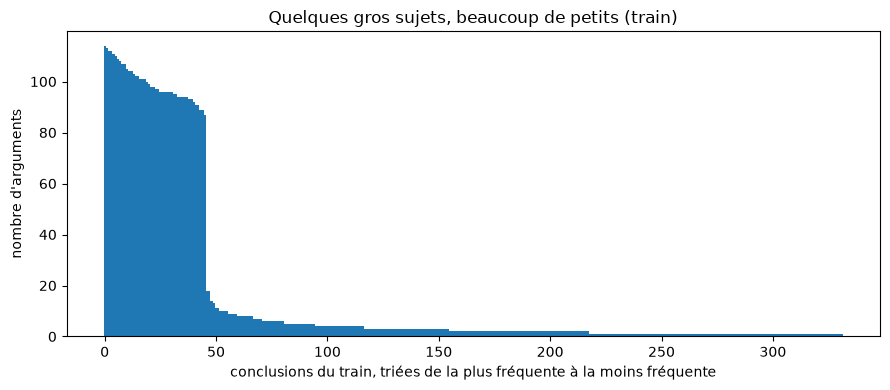

conclusion
We should abolish the three-strikes laws                114
We should abolish capital punishment                    113
We should fight for the abolition of nuclear weapons    112
We should legalize prostitution                         112
We should stop the development of autonomous cars       111
We should legalize cannabis                             110
We should ban cosmetic surgery for minors               109
We should abandon the use of school uniform             108
We should ban the Church of Scientology                 107
We should introduce compulsory voting                   107
Name: count, dtype: int64

In [8]:
c = train.conclusion.value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(c)), c.values, width=1)
ax.set(xlabel="conclusions du train, triées de la plus fréquente à la moins fréquente",
       ylabel="nombre d'arguments", title="Quelques gros sujets, beaucoup de petits (train)")
plt.tight_layout(); plt.savefig("../figures/audit_conclusions_train.png", dpi=120); plt.show()
c.head(10)

**Lecture :** une « longue traîne ». ~50 gros sujets (source IBM, ~110 arguments chacun) dominent, puis des centaines de sujets avec 1–2 arguments.
Risque : le modèle apprend « sujet → valeurs » au lieu de lire la prémisse (**raccourci de sujet**).

In [9]:
norm = lambda x: " ".join(x.lower().split()).rstrip(".")
lignes = []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    lignes.append({"paire": f"{a} ∩ {b}",
                   "conclusions communes (exact)": len(set(d[a].conclusion) & set(d[b].conclusion)),
                   "après normalisation": len(set(d[a].conclusion.map(norm)) & set(d[b].conclusion.map(norm)))})
pd.DataFrame(lignes)

,paire,conclusions communes (exact),après normalisation
0,train ∩ val,0,0
1,train ∩ test,0,0
2,val ∩ test,0,0


**Lecture :** 0 conclusion commune. Le README disait vrai : *une même conclusion est toujours dans le même split*.
- Bonne nouvelle : val et test portent sur des **sujets jamais vus** → le raccourci « mémoriser la conclusion » ne peut pas gonfler nos scores.
- Conséquence pour **F3** (« conclusion vue / non vue ») : le groupe « vue » est vide au sens exact → on utilisera une notion de **sujet proche** (similarité sémantique).

## 4. Doublons d'arguments

Un **doublon** = le même argument complet (conclusion + position + prémisse) présent sur deux lignes, avec deux `id` différents.
On compare de deux façons :
- **exact** : caractère pour caractère ;
- **normalisé** : minuscules, ponctuation retirée, espaces multiples réduits (« Hello, World » = « hello world »).

In [10]:
import re

def normaliser(x):
    x = re.sub(r"[^\w\s]", " ", x.lower())   # minuscules + ponctuation -> espace
    return re.sub(r"\s+", " ", x).strip()      # espaces multiples -> un seul

for df in d.values():
    df["cle_exacte"] = df.conclusion + "|" + df.stance + "|" + df.premise
    df["cle_norm"] = df.conclusion.map(normaliser) + "|" + df.stance + "|" + df.premise.map(normaliser)

lignes = [{"split": nom, "doublons exacts": int(df.cle_exacte.duplicated().sum()),
           "doublons après normalisation": int(df.cle_norm.duplicated().sum())} for nom, df in d.items()]
lignes += [{"split": f"{a} ∩ {b}", "doublons exacts": len(set(d[a].cle_exacte) & set(d[b].cle_exacte)),
            "doublons après normalisation": len(set(d[a].cle_norm) & set(d[b].cle_norm))}
           for a, b in [("train", "val"), ("train", "test"), ("val", "test")]]
pd.DataFrame(lignes)

,split,doublons exacts,doublons après normalisation
0,train,80,91
1,val,33,35
2,test,28,32
3,train ∩ val,0,0
4,train ∩ test,0,0
5,val ∩ test,0,0


**Lecture :** des doublons existent **à l'intérieur** de chaque split (91 dans train), mais **aucun entre splits** → pas de fuite du train vers le test.

Regardons-les de près : d'où viennent-ils, et ont-ils les mêmes labels ?

In [11]:
paires = []
for nom, df in d.items():
    for _, g in df[df.cle_norm.duplicated(keep=False)].groupby("cle_norm"):
        a, b = g.iloc[0], g.iloc[1]
        paires.append({"split": nom, "id_1": a.id, "id_2": b.id, "prémisse": a.premise[:60] + "…",
                       "valeurs copie 1": [v for v in VALUES if a[v]], "valeurs copie 2": [v for v in VALUES if b[v]],
                       "identiques": bool((a[VALUES] == b[VALUES]).all())})
paires = pd.DataFrame(paires)
print("taille des groupes : toujours 2 (des paires)")
print("source (1re lettre de l'id) :", pd.concat([paires.id_1, paires.id_2]).str[0].value_counts().to_dict())
print(f"paires aux labels identiques : {paires.identiques.sum()} / {len(paires)}")
paires.head(6)

taille des groupes : toujours 2 (des paires)
source (1re lettre de l'id) : {'E': 312, 'D': 4}
paires aux labels identiques : 6 / 158


,split,id_1,id_2,prémisse,valeurs copie 1,valeurs copie 2,identiques
0,train,E04062,E07206,If asylum applications are filed from abroad the costs for E…,[Security: personal],"[Security: personal, Conformity: rules, Benevolence: dependability]",False
1,train,E04063,E07207,If asylum applications are filed from abroad the humanitaria…,"[Security: personal, Benevolence: caring, Universalism: concern]","[Security: societal, Benevolence: dependability, Universalism: concern]",False
2,train,E04064,E07208,If asylum applications are filed from abroad the security ri…,"[Security: societal, Universalism: concern]","[Security: societal, Benevolence: dependability]",False
3,train,E04034,E07209,We need to accept more immigrants to combat the aging of the…,"[Achievement, Security: societal]","[Security: societal, Conformity: rules, Benevolence: caring, Universalism: objectivity]",False
4,train,E04039,E07217,If young Europeans are living abroad they will feel racism o…,"[Security: personal, Universalism: concern, Universalism: tolerance]","[Stimulation, Achievement, Security: personal, Humility, Benevolence: caring, Universalism: concern, Universalism: t...",False
5,train,E04040,E07218,No duck would like to live with eagles or sparrows. That's …,"[Self-direction: action, Security: personal, Universalism: nature]",[Self-direction: action],False


**Lecture :** ce sont des **paires**, presque toutes de la source **E** (Conférence sur l'avenir de l'Europe) :
le même commentaire a été collecté deux fois (ids `E04xxx` et `E07xxx`) et **annoté deux fois indépendamment**.
Résultat : **96 % des paires ont des labels contradictoires.**

C'est une chance : ces paires mesurent **l'accord entre annotateurs humains**. Traitons la copie 1 comme une « prédiction » de la copie 2 :

In [12]:
import numpy as np
from sklearn.metrics import f1_score

def vecteur(noms):
    return [int(v in noms) for v in VALUES]

c1 = np.array([vecteur(x) for x in paires["valeurs copie 1"]])
c2 = np.array([vecteur(x) for x in paires["valeurs copie 2"]])
print(f"Accord humain sur {len(paires)} paires : macro-F1 = {f1_score(c2, c1, average='macro', zero_division=0):.3f}, "
      f"micro-F1 = {f1_score(c2, c1, average='micro'):.3f}")

Accord humain sur 158 paires : macro-F1 = 0.415, micro-F1 = 0.532


**Lecture :** deux annotations humaines du **même texte** ne s'accordent qu'à **macro-F1 ≈ 0,42**.
C'est un ordre de grandeur du **plafond** atteignable : un modèle ne peut pas être « plus d'accord » avec les labels que les humains entre eux.
(Prudence : 158 paires seulement, toutes de la source E — à confirmer, mais à garder en tête pour juger nos scores et pour F6 / Q12.)

### Politique pour les doublons (décision justifiée)
| Où | Décision | Pourquoi |
|---|---|---|
| **train** | on **garde les deux copies** | Les deux annotations sont aussi valables l'une que l'autre ; on ne sait pas laquelle est « juste ». Garder les deux revient à apprendre une étiquette **moyenne** : 1 si les deux annotateurs sont d'accord, « 0,5 » s'ils divergent. Supprimer perdrait 182 lignes ; l'union inventerait des positifs ; l'intersection en effacerait. |
| **val / test** | on **ne touche à rien** | Ce sont les jeux officiels : les modifier rendrait nos scores incomparables à la littérature. Le bruit fait partie de la difficulté réelle. |
| **entre splits** | rien à faire | 0 doublon entre splits → aucune fuite. |